# Libraries

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
import pandas as pd
pd.set_option('display.max_colwidth', None)  # otherwise the 'params' dict column gets cut off
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.utils import Bunch

sys.path.append(str(Path.cwd().parent))
from sklearn.metrics import make_scorer
import matplotlib.pyplot as plt

# Data

In [2]:
processed_dir = Path("../data")
file_pat_fd001_train = processed_dir / f"labeled_train_FD001.csv"
train_df = pd.read_csv(file_pat_fd001_train)


index_names = ['engine_id', 'cycle']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = [f'sensor_{i}' for i in range(1, 22)]

excluded_columns = ['sensor_1', 'sensor_19', 'sensor_18', 'sensor_10', 'sensor_16', 'sensor_5', 'sensor_6']
selected_sensors = [sensor for sensor in sensor_names if sensor not in excluded_columns]
features = selected_sensors + ['cycle']

X_train = train_df[features]
y_train = train_df['rul_limited']
groups = train_df['engine_id']
X_train.shape

(20631, 15)

In [3]:
X_train.describe()

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,cycle
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,642.680934,1590.523119,1408.933782,553.367711,2388.096652,9065.242941,47.541168,521.413470,2388.096152,8143.752722,8.442146,393.210654,38.816271,23.289705,108.807862
std,0.500053,6.131150,9.000605,0.885092,0.070985,22.082880,0.267087,0.737553,0.071919,19.076176,0.037505,1.548763,0.180746,0.108251,68.880990
min,641.210000,1571.040000,1382.250000,549.850000,2387.900000,9021.730000,46.850000,518.690000,2387.880000,8099.940000,8.324900,388.000000,38.140000,22.894200,1.000000
25%,642.325000,1586.260000,1402.360000,552.810000,2388.050000,9053.100000,47.350000,520.960000,2388.040000,8133.245000,8.414900,392.000000,38.700000,23.221800,52.000000
50%,642.640000,1590.100000,1408.040000,553.440000,2388.090000,9060.660000,47.510000,521.480000,2388.090000,8140.540000,8.438900,393.000000,38.830000,23.297900,104.000000
75%,643.000000,1594.380000,1414.555000,554.010000,2388.140000,9069.420000,47.700000,521.950000,2388.140000,8148.310000,8.465600,394.000000,38.950000,23.366800,156.000000
max,644.530000,1616.910000,1441.490000,556.060000,2388.560000,9244.590000,48.530000,523.380000,2388.560000,8293.720000,8.584800,400.000000,39.430000,23.618400,362.000000


# Scores

### Nasa Score

In [4]:
def nasa_score(y_true, y_pred):
    # Late predictions (d >= 0) must cost more than early ones d < 0
    d = np.asarray(y_pred) - np.asarray(y_true)
    scores = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return scores.mean()


nasa_scorer = make_scorer(nasa_score, greater_is_better=False)

In [5]:
scoring = {
    'mse': 'neg_mean_squared_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
    'nasa': nasa_scorer,
}

### groups K folds

In [6]:
gkf = GroupKFold(n_splits=5)

# Noise Treatment

In [7]:
def scale_if_ridge(model):
    # Ridge is scale-sensitive; the tree models (RF, HistGB) are not, so they run raw.
    return make_pipeline(StandardScaler(), model) if isinstance(model, Ridge) else model

### Moving Averange test

In [8]:
def moving_average_features(window):
    if window == 0:
        X_w = train_df[selected_sensors + ['cycle']]
    else:
        rolling_cols = train_df.groupby('engine_id')[selected_sensors].rolling(window=window, min_periods=1).mean()
        rolling_cols = rolling_cols.reset_index(level=0, drop=True)
        rolling_cols.columns = [f"{c}_ma{window}" for c in selected_sensors]
        X_w = rolling_cols.join(train_df['cycle'])
    y_w = train_df['rul_limited']
    groups_w = train_df['engine_id']
    return X_w, y_w, groups_w


def window_comparison(model, model_name, windows=(0, 2, 3, 5, 20)):
    rows = []
    for window in windows:
        X_w, y_w, groups_w = moving_average_features(window)
        cv = cross_validate(scale_if_ridge(model), X_w, y_w, groups=groups_w, cv=gkf, scoring=scoring, n_jobs=-1)
        rows.append({
            'model': model_name, 'window': window,
            'R2_mean': cv['test_r2'].mean(),
            'R2_std': cv['test_r2'].std(),
            'RMSE_mean': -cv['test_rmse'].mean(),
        })
    return pd.DataFrame(rows)

### Windows test

In [9]:

window_results = pd.concat([
        window_comparison(Ridge(), 'Ridge'),
        window_comparison(RandomForestRegressor(random_state=42), 'Random Forest'),
        window_comparison(HistGradientBoostingRegressor(random_state=42), 'HistGradientBoosting'),
], ignore_index=True)

window_results.sort_values(['model', 'R2_mean'], ascending=False).reset_index(drop=True)

,model,window,R2_mean,R2_std,RMSE_mean
0,Ridge,3,0.769823,0.031426,19.943846
1,Ridge,2,0.769667,0.031368,19.950900
2,Ridge,5,0.767786,0.031542,20.032338
3,Ridge,0,0.765813,0.031242,20.119291
4,Ridge,20,0.741319,0.033239,21.148809
5,Random Forest,2,0.839733,0.012852,16.668889
6,Random Forest,3,0.838104,0.012999,16.753725
7,Random Forest,0,0.837178,0.013354,16.800672
8,Random Forest,5,0.836279,0.015085,16.844084
9,Random Forest,20,0.800022,0.021598,18.606453


### Set moving averange (window = 3)

In [10]:
# Moving average (rolling mean) smoothing, window=3

window = 3
n_rows = len(train_df)
train_df = train_df.sort_values(index_names) 

rolling_cols = train_df.groupby('engine_id')[selected_sensors].rolling(window=window, min_periods=1).mean()
rolling_cols = rolling_cols.reset_index(level=0, drop=True)
rolling_cols.columns = [f"{c}_ma{window}" for c in selected_sensors]
train_df = train_df.join(rolling_cols)

features = rolling_cols.columns.tolist() + ['cycle']
X_train = train_df[features]
y_train = train_df['rul_limited']
groups = train_df['engine_id']

assert X_train.shape[0] == n_rows 
assert X_train.isna().sum().sum() == 0 
X_train.shape

(20631, 15)

In [11]:
smoothed_cols = rolling_cols.columns.tolist()

### Comparison graphs-  Smoothed vs raw data

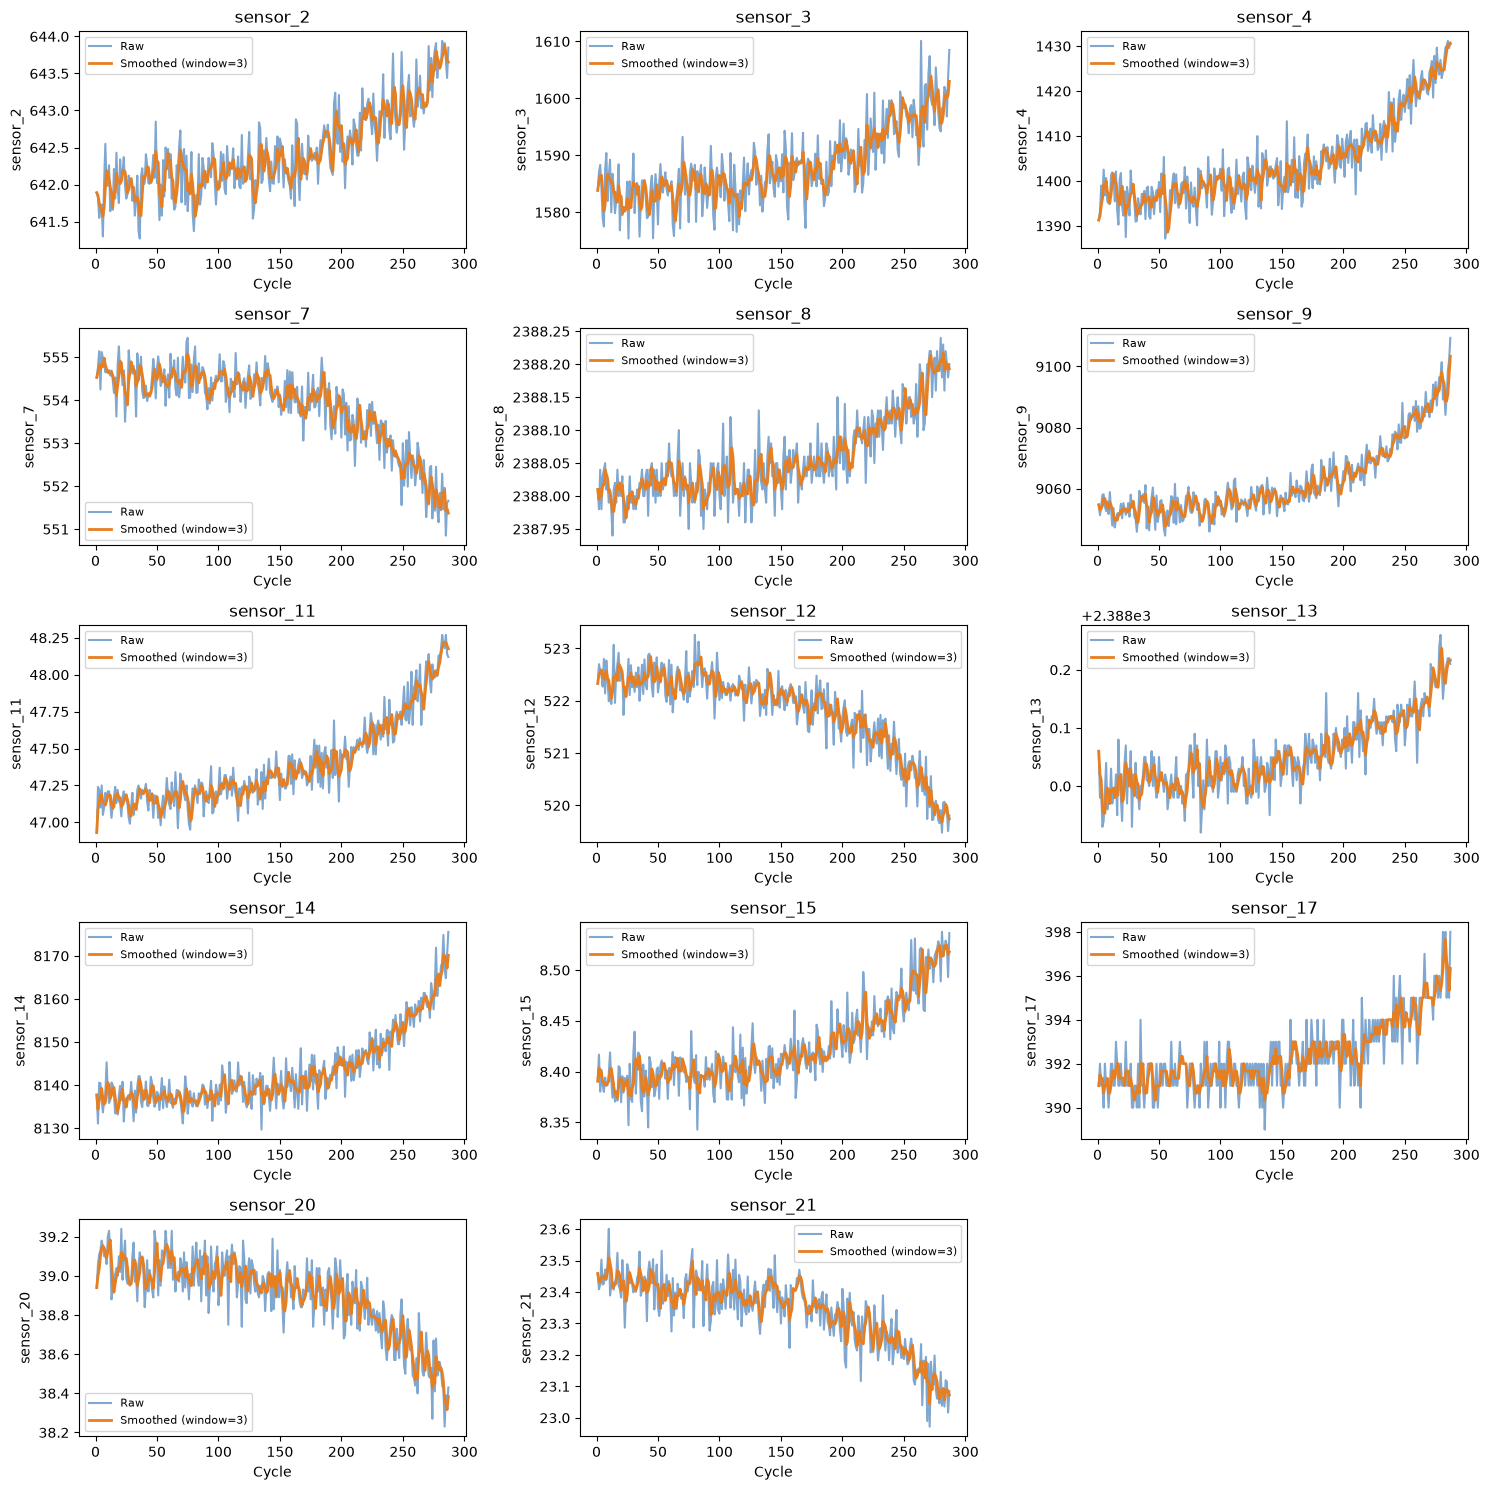

In [14]:
# One engine, all sensors: raw vs smoothed (window=3) to see what the rolling mean above actually does
engine_example = train_df[train_df['engine_id'] == 2].sort_values('cycle')

n_cols = 3
n_rows = int(np.ceil(len(selected_sensors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3 * n_rows))
axes = axes.ravel()

for ax, sensor in zip(axes, selected_sensors):
    ax.plot(engine_example['cycle'], engine_example[sensor], label='Raw', color='#2b6cb0', alpha=0.6)
    ax.plot(engine_example['cycle'], engine_example[f'{sensor}_ma{window}'],
             label=f'Smoothed (window={window})', color='#e67e22', linewidth=2)
    ax.set_xlabel('Cycle')
    ax.set_ylabel(sensor)
    ax.set_title(sensor)
    ax.legend(fontsize=8)

for ax in axes[len(selected_sensors):]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('../outputs/smoothed_sensors.png')
plt.show()

### Slope feature test

In [15]:
def trend_features(window):
    if window == 0:
        X_t = train_df[smoothed_cols + ['cycle']]
    else:
        slope_cols = train_df.groupby('engine_id')[smoothed_cols].diff(window) / window
        slope_cols.columns = [f"{c}_slope{window}" for c in smoothed_cols]
        X_t = train_df[smoothed_cols + ['cycle']].join(slope_cols).fillna(0)
    y_t = train_df['rul_limited']
    groups_t = train_df['engine_id']
    return X_t, y_t, groups_t


def trend_comparison(model, model_name, windows=(0, 5, 10, 15, 20)):
    rows = []
    for window in windows:
        X_t, y_t, groups_t = trend_features(window)
        cv = cross_validate(scale_if_ridge(model), X_t, y_t, groups=groups_t, cv=gkf, scoring=scoring, n_jobs=-1)
        rows.append({
            'model': model_name, 'window': window,
            'R2_mean': cv['test_r2'].mean(),
            'R2_std': cv['test_r2'].std(),
            'RMSE_mean': -cv['test_rmse'].mean(),
        })
    return pd.DataFrame(rows)

In [16]:
trend_results = pd.concat([
        trend_comparison(Ridge(), 'Ridge'),
        trend_comparison(RandomForestRegressor(random_state=42), 'Random Forest'),
        trend_comparison(HistGradientBoostingRegressor(random_state=42), 'HistGradientBoosting'),
], ignore_index=True)

trend_results.sort_values(['model', 'R2_mean'], ascending=False).reset_index(drop=True)

,model,window,R2_mean,R2_std,RMSE_mean
0,Ridge,20,0.822934,0.013739,17.522044
1,Ridge,15,0.809977,0.016479,18.148308
2,Ridge,10,0.793101,0.020230,18.931957
3,Ridge,5,0.775513,0.027393,19.705974
4,Ridge,0,0.769823,0.031426,19.943846
5,Random Forest,20,0.881040,0.006540,14.367807
6,Random Forest,15,0.869020,0.007459,15.075708
7,Random Forest,10,0.854383,0.006954,15.897665
8,Random Forest,5,0.842998,0.010683,16.502483
9,Random Forest,0,0.838104,0.012999,16.753725


### Set Slope of change per sensor

In [17]:
# Slope (rate of change), window=20: the one technique whose removal dropped R2 by
window_slope = 20
n_rows = len(train_df)

slope_cols = train_df.groupby('engine_id')[smoothed_cols].diff(window_slope) / window_slope
slope_cols.columns = [f"{c}_slope{window_slope}" for c in smoothed_cols]
slope_cols = slope_cols.fillna(0) 
train_df = train_df.join(slope_cols)

features = features + slope_cols.columns.tolist()
X_train = train_df[features]

assert X_train.shape[0] == n_rows 
assert X_train.isna().sum().sum() == 0  
X_train.shape

(20631, 29)

### Data X test

In [18]:
X_train.describe()

,sensor_2_ma3,sensor_3_ma3,sensor_4_ma3,sensor_7_ma3,sensor_8_ma3,sensor_9_ma3,sensor_11_ma3,sensor_12_ma3,sensor_13_ma3,sensor_14_ma3,...,sensor_8_ma3_slope20,sensor_9_ma3_slope20,sensor_11_ma3_slope20,sensor_12_ma3_slope20,sensor_13_ma3_slope20,sensor_14_ma3_slope20,sensor_15_ma3_slope20,sensor_17_ma3_slope20,sensor_20_ma3_slope20,sensor_21_ma3_slope20
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,...,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,642.674485,1590.446267,1408.799110,553.380347,2388.095745,9065.032154,47.537131,521.424088,2388.095216,8143.604629,...,0.000687,0.166617,0.003216,-8.528190e-03,0.000701,0.116623,0.000418,0.016325,-0.001964,-0.001195
std,0.429922,5.134326,8.267217,0.810710,0.065705,21.339784,0.250644,0.686737,0.066600,18.494433,...,0.001475,0.429754,0.005254,1.523024e-02,0.001493,0.363321,0.000899,0.041722,0.004458,0.002632
min,641.450000,1573.020000,1387.306667,550.670000,2387.920000,9027.036667,46.930000,519.036667,2387.930000,8102.913333,...,-0.004167,-0.887000,-0.015667,-8.150000e-02,-0.004667,-0.832833,-0.003745,-0.166667,-0.022167,-0.012118
25%,642.363333,1586.776667,1402.615000,552.896667,2388.046667,9053.556667,47.346667,521.015000,2388.046667,8133.391667,...,-0.000167,-0.040167,0.000000,-1.783333e-02,-0.000167,-0.054583,-0.000107,-0.016667,-0.004833,-0.002900
50%,642.626667,1589.863333,1407.800000,553.453333,2388.093333,9060.410000,47.510000,521.483333,2388.093333,8140.460000,...,0.000500,0.058833,0.002333,-6.500000e-03,0.000500,0.023833,0.000312,0.016667,-0.001500,-0.000872
75%,642.940000,1593.480000,1413.790000,553.996667,2388.136667,9068.671667,47.685000,521.950000,2388.136667,8147.945000,...,0.001500,0.246667,0.006333,5.684342e-15,0.001667,0.180167,0.000995,0.050000,0.000667,0.000323
max,644.196667,1610.396667,1435.143333,555.376667,2388.446667,9230.333333,48.330000,523.003333,2388.440000,8287.280000,...,0.019500,3.796167,0.028500,4.066667e-02,0.020000,3.162333,0.004238,0.200000,0.015667,0.008643


# PCA Analisis

In [19]:
pca_pipe = make_pipeline(StandardScaler(), PCA(random_state=42))
pca_pipe.fit(X_train)
pca = pca_pipe.named_steps['pca']
cum_variance = np.cumsum(pca.explained_variance_ratio_)

print('Cumulative variance')
print(cum_variance)
print(f"\nPC1 explains {pca.explained_variance_ratio_[0]:.1%} of the variance")
components_needed = {}
for target in [0.50, 0.80, 0.90, 0.95]:
    components_needed[target] = int(np.searchsorted(cum_variance, target, side='right')) + 1
    print(f"{target:.0%} of the variance kept  {components_needed[target]} components")

Cumulative variance
[0.48406939 0.61051876 0.66243693 0.6944869  0.72544171 0.75577205
 0.78388502 0.81177632 0.83821502 0.86293752 0.88673429 0.90945364
 0.93125777 0.95095724 0.96763895 0.97359847 0.97800334 0.98134208
 0.9842954  0.98703314 0.9893322  0.99153313 0.99340677 0.99490782
 0.99627636 0.9975452  0.99877757 0.99980317 1.        ]

PC1 explains 48.4% of the variance
50% of the variance kept  2 components
80% of the variance kept  8 components
90% of the variance kept  12 components
95% of the variance kept  14 components


In [20]:
def run_pca_ridge_one_se():
    pca_ridge_pipe = make_pipeline(StandardScaler(), PCA(random_state=42), Ridge())
    pca_ridge_param_grid = {'pca__n_components': [0.50,0.80, 0.90, 0.95]}
    pca_gkf = GroupKFold(n_splits=5)

    pca_ridge_search = GridSearchCV(
        estimator=pca_ridge_pipe,
        param_grid=pca_ridge_param_grid,
        cv=pca_gkf,
        scoring=scoring,
        refit='r2',
        n_jobs=-1,
    )
    pca_ridge_search.fit(X_train, y_train, groups=groups)

    pca_ridge_cv = pca_ridge_search.cv_results_
    i = pca_ridge_search.best_index_
    print(f"PCA_with not tunning: \nbest_params={pca_ridge_search.best_params_}, "
          f"RMSE={-pca_ridge_cv['mean_test_rmse'][i]:.4f}, "
          f"R²={pca_ridge_cv['mean_test_r2'][i]:.4f}\n ")

    best_params = pca_ridge_cv['params'][i]

    se = pca_ridge_cv['std_test_r2'][i] / np.sqrt(pca_ridge_search.n_splits_)
    threshold = pca_ridge_cv['mean_test_r2'][i] - se

    n_one_se = min(
        params['pca__n_components']
        for params, mean in zip(pca_ridge_cv['params'], pca_ridge_cv['mean_test_r2'])
        if mean >= threshold
        and params['pca__n_components'] is not None
    )

    selected = make_pipeline(StandardScaler(), PCA(n_components=n_one_se, random_state=42),
                              PolynomialFeatures(), StandardScaler(),
                              Ridge())

    baseline = make_pipeline(StandardScaler(), PolynomialFeatures(), StandardScaler(), Ridge())

    for name, model in [('One-SE PCA', selected),
                         ('Max-CV PCA', pca_ridge_search.best_estimator_),
                         ('No PCA', baseline)]:
        cv = cross_validate(model, X_train, y_train, cv=pca_gkf, groups=groups, scoring=scoring)
        print(f"{name}: r2={cv['test_r2'].mean():.3f} (±{cv['test_r2'].std():.3f})")

run_pca_ridge_one_se()


PCA_with not tunning: 
best_params={'pca__n_components': 0.95}, RMSE=18.1639, R²=0.8096
 
One-SE PCA: r2=0.842 (±0.011)
Max-CV PCA: r2=0.810 (±0.018)
No PCA: r2=0.854 (±0.009)


# Dummy Regression

In [21]:
def dummy(X, y, groups, scoring):
    return cross_validate(
        DummyRegressor(strategy="mean"), X, y,
        cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring,)

groups = train_df['engine_id']

dummy_results = dummy(X_train, y_train, groups, scoring)
print(f"Dummy: RMSE = {-dummy_results['test_rmse'].mean():.2f} "
      f"(±{dummy_results['test_rmse'].std():.2f}), "
      f"R² = {dummy_results['test_r2'].mean():.3f}, "
      f'Nasa = {-dummy_results['test_nasa'].mean():.4f}')

Dummy: RMSE = 41.67 (±0.00), R² = -0.000, Nasa = 308.0393


# Ridge

In [22]:
def ridge_regression(X, y, groups, gkf, scoring):
    ridge_pipe = make_pipeline(StandardScaler(),PolynomialFeatures(2), StandardScaler(), Ridge())
    ridge_param_grid = {
        # 'pca__n_components': [0.90, 0.95, 0.99, None],
        # 'polynomialfeatures__degree':[1,2],
        'ridge__alpha': [100, 500, 1000,2000,10_000],
    }

    ridge_search = GridSearchCV(
        estimator=ridge_pipe,
        param_grid=ridge_param_grid,
        cv=gkf,
        scoring=scoring,
        refit='r2',
        n_jobs=-1,
    )
    ridge_search.fit(X, y, groups=groups)

    ridge_cv = ridge_search.cv_results_
    ridge_results_table = pd.DataFrame({
        'params': ridge_cv['params'],
        'R2_mean': ridge_cv['mean_test_r2'],
        'R2_std': ridge_cv['std_test_r2'],
        'RMSE_mean': -ridge_cv['mean_test_rmse'],
        'RMSE_std': ridge_cv['std_test_rmse'],
        'MSE_mean': -ridge_cv['mean_test_mse'],
        'NASA_mean': -ridge_cv['mean_test_nasa'],
        'NASA_std': ridge_cv['std_test_nasa'],
    }).sort_values('R2_mean', ascending=False).reset_index(drop=True)
    return ridge_search, ridge_results_table


ridge_search, ridge_results_table = ridge_regression(X_train, y_train, groups, gkf, scoring)
print("Ridge: ")
ridge_results_table

Ridge: 


,params,R2_mean,R2_std,RMSE_mean,RMSE_std,MSE_mean,NASA_mean,NASA_std
0,{'ridge__alpha': 500},0.858072,0.009098,15.691232,0.509026,246.473868,4.092043,0.690568
1,{'ridge__alpha': 1000},0.857879,0.009219,15.701634,0.517432,246.809037,4.108126,0.678565
2,{'ridge__alpha': 100},0.856718,0.009125,15.766119,0.504769,248.825300,4.140927,0.704312
3,{'ridge__alpha': 2000},0.856441,0.009575,15.780346,0.536180,249.306813,4.164565,0.658654
4,{'ridge__alpha': 10000},0.843368,0.011512,16.481276,0.614925,272.010591,4.560737,0.565399


### Polynomial feature impact

In [23]:

poly_degree_2 = make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), Ridge())
without_poly = make_pipeline(StandardScaler(), Ridge())

for name, model in [
                     ('PolynomialFeatures degree=2', poly_degree_2),
                     ('Without PolynomialFeatures', without_poly)]:
    cv = cross_validate(model, X_train, y_train, cv=gkf, groups=groups, scoring=scoring)
    print(f"{name}: r2={cv['test_r2'].mean():.3f} (±{cv['test_r2'].std():.3f})")


PolynomialFeatures degree=2: r2=0.854 (±0.009)
Without PolynomialFeatures: r2=0.823 (±0.014)


In [24]:
ridge_pipe = make_pipeline(StandardScaler(),PolynomialFeatures(2), StandardScaler(), Ridge(alpha = 2000))
start = time.perf_counter()
ridge_pipe.fit(X_train,y_train)
print(f"Ridge training time: {time.perf_counter() - start:.2f} s")
ridge_choosen = cross_validate(ridge_pipe, X_train, y_train, cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)

Ridge training time: 0.19 s


# Lasso

In [25]:

# lasso_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), Lasso(max_iter=1000, random_state=42))
# lasso_param_grid = {'lasso__alpha': [0.9, 0.11]}

# lasso_search = GridSearchCV(
#     estimator=lasso_pipe,
#     param_grid=lasso_param_grid,
#     cv=gkf,
#     scoring=scoring,
#     refit='r2',
#     n_jobs=-1,
# )
# lasso_search.fit(X_train, y_train, groups=groups)

# lasso_cv = lasso_search.cv_results_
# i = lasso_search.best_index_
# print(f"Lasso: alpha={lasso_search.best_params_['lasso__alpha']}, "
#       f"R²={lasso_cv['mean_test_r2'][i]:.4f}, "
#       f"RMSE={-lasso_cv['mean_test_rmse'][i]:.4f} (±{lasso_cv['std_test_rmse'][i]:.4f}), "
#       f"MSE={-lasso_cv['mean_test_mse'][i]:.4f}, "
#       f"NASA={-lasso_cv['mean_test_nasa'][i]:.4f} (±{lasso_cv['std_test_nasa'][i]:.4f})")

# Random Forest Regresor

In [25]:
def random_forest(X, y, groups, gkf, scoring):
    rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=300, max_features='sqrt',oob_score=True, random_state=42))
    rf_param_grid = {
        'randomforestregressor__max_depth': [None,5,15,30],
        'randomforestregressor__min_samples_leaf': [1, 10, 20],
    }

    rf_search = GridSearchCV(
        estimator=rf_pipe,
        param_grid=rf_param_grid,
        cv=gkf,
        scoring=scoring,
        refit='r2',
        n_jobs=-1,
    )
    rf_search.fit(X, y, groups=groups)

    rf_cv = rf_search.cv_results_
    rf_results_table = pd.DataFrame({
        'params': rf_cv['params'],
        'R2_mean': rf_cv['mean_test_r2'],
        'R2_std': rf_cv['std_test_r2'],
        'RMSE_mean': -rf_cv['mean_test_rmse'],
        'RMSE_std': rf_cv['std_test_rmse'],
        'MSE_mean': -rf_cv['mean_test_mse'],
        'NASA_mean': -rf_cv['mean_test_nasa'],
        'NASA_std': rf_cv['std_test_nasa'],
    }).sort_values('R2_mean', ascending=False).reset_index(drop=True)
    return rf_search, rf_results_table


rf_search, rf_results_table = random_forest(X_train, y_train, groups, gkf, scoring)
print("Random Forest")
rf_results_table

Random Forest


,params,R2_mean,R2_std,RMSE_mean,RMSE_std,MSE_mean,NASA_mean,NASA_std
0,"{'randomforestregressor__max_depth': 30, 'randomforestregressor__min_samples_leaf': 1}",0.886997,0.008138,13.999643,0.503347,196.243375,3.557686,0.356695
1,"{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 1}",0.886922,0.008245,14.004088,0.509656,196.374217,3.565127,0.361351
2,"{'randomforestregressor__max_depth': 15, 'randomforestregressor__min_samples_leaf': 1}",0.886737,0.008216,14.015585,0.508555,196.695258,3.628164,0.393399
3,"{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 10}",0.884736,0.008947,14.137562,0.547380,200.170276,3.631988,0.372407
4,"{'randomforestregressor__max_depth': 30, 'randomforestregressor__min_samples_leaf': 10}",0.884736,0.008947,14.137562,0.547380,200.170276,3.631988,0.372407
5,"{'randomforestregressor__max_depth': 15, 'randomforestregressor__min_samples_leaf': 10}",0.884719,0.008807,14.138925,0.538799,200.199494,3.665723,0.381671
6,"{'randomforestregressor__max_depth': 15, 'randomforestregressor__min_samples_leaf': 20}",0.881650,0.009725,14.324159,0.590283,205.529967,3.733692,0.411361
7,"{'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 20}",0.881539,0.009862,14.330581,0.597157,205.722141,3.743620,0.421092
8,"{'randomforestregressor__max_depth': 30, 'randomforestregressor__min_samples_leaf': 20}",0.881539,0.009862,14.330581,0.597157,205.722141,3.743620,0.421092
9,"{'randomforestregressor__max_depth': 5, 'randomforestregressor__min_samples_leaf': 1}",0.849392,0.013708,16.155408,0.742843,261.549013,5.650494,1.062274


Random Forest training time: 2.33 s


<Axes: >

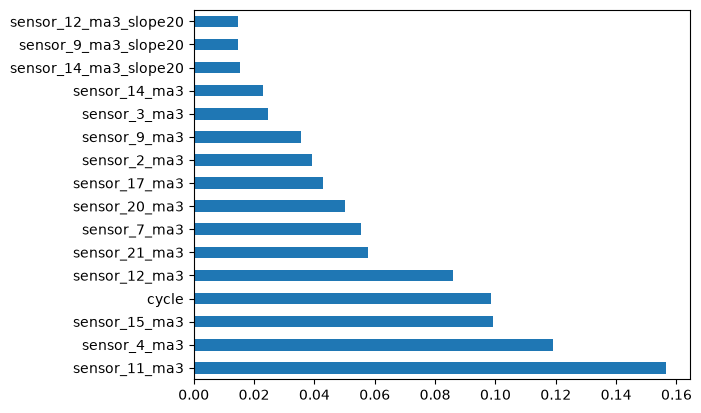

In [26]:

RandomForest_pipeline = make_pipeline(
    RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=20,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )
)
start = time.perf_counter()
RandomForest_pipeline.fit(X_train, y_train)
print(f"Random Forest training time: {time.perf_counter() - start:.2f} s")
rf_choosen = cross_validate(RandomForest_pipeline, X_train, y_train, cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)

rf_model = RandomForest_pipeline.named_steps['randomforestregressor']
rf_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
rf_importances.nlargest(16).plot(kind='barh')

In [27]:
top_n_values = [3, 5, 8, 10, len(rf_importances)]

rf_topn_rows = []
for top_n in top_n_values:
    top_features = rf_importances.nlargest(top_n).index.tolist()
    cv = cross_validate(rf_model, X_train[top_features], y_train, groups=groups, cv=gkf, scoring=scoring, n_jobs=-1)
    
    rf_topn_rows.append({
        'top_columns': top_n,
        'R2_mean': cv['test_r2'].mean(),
        'RMSE_mean': -cv['test_rmse'].mean(), 'RMSE_std': cv['test_rmse'].std(),
        'NASA_mean': -cv['test_nasa'].mean(), 'NASA_std': cv['test_nasa'].std(),
    })

rf_topn_comparison = pd.DataFrame(rf_topn_rows).sort_values('R2_mean',ascending=False).reset_index(drop=True)
rf_topn_comparison

,top_columns,R2_mean,RMSE_mean,RMSE_std,NASA_mean,NASA_std
0,29,0.881349,14.342336,0.591529,3.741335,0.423430
1,10,0.824691,17.400663,1.288659,6.171445,1.140330
2,8,0.820086,17.627414,1.309410,6.478254,1.213759
3,5,0.819237,17.669945,1.299007,6.564413,1.180903
4,3,0.723143,21.874756,1.513834,17.685315,5.888679


# Gradient Boosting

In [28]:

def gradient_boosting(X, y, groups, gkf, scoring):
    hgb_pipe = make_pipeline(HistGradientBoostingRegressor(learning_rate= 0.05, max_depth= 2,max_iter=2000, early_stopping=True, random_state=42))
    hgb_param_grid = {
        'histgradientboostingregressor__max_depth': [3, 4, 6, None],
    }

    hgb_search = GridSearchCV(
        estimator=hgb_pipe,
        param_grid=hgb_param_grid,
        cv=gkf,
        scoring=scoring,
        refit='r2',
        n_jobs=-1,
    )
    hgb_search.fit(X, y, groups=groups)

    hgb_cv = hgb_search.cv_results_
    hgb_results_table = pd.DataFrame({
        'params': hgb_cv['params'],
        'R2_mean': hgb_cv['mean_test_r2'],
        'R2_std': hgb_cv['std_test_r2'],
        'RMSE_mean': -hgb_cv['mean_test_rmse'],
        'RMSE_std': hgb_cv['std_test_rmse'],
        'MSE_mean': -hgb_cv['mean_test_mse'],
        'NASA_mean': -hgb_cv['mean_test_nasa'],
        'NASA_std': hgb_cv['std_test_nasa'],
    }).sort_values('R2_mean', ascending=False).reset_index(drop=True)
    return hgb_search, hgb_results_table


hgb_search, hgb_results_table = gradient_boosting(X_train, y_train, groups, gkf, scoring)
print("HistGradientBoosting:")
hgb_results_table


HistGradientBoosting:


,params,R2_mean,R2_std,RMSE_mean,RMSE_std,MSE_mean,NASA_mean,NASA_std
0,{'histgradientboostingregressor__max_depth': 4},0.888597,0.007649,13.900838,0.481174,193.464836,3.668617,0.611625
1,{'histgradientboostingregressor__max_depth': 3},0.888101,0.008100,13.930784,0.508672,194.325503,3.613342,0.631053
2,{'histgradientboostingregressor__max_depth': None},0.887404,0.006809,13.977023,0.424076,195.537018,3.870288,0.624437
3,{'histgradientboostingregressor__max_depth': 6},0.887217,0.007998,13.986157,0.499484,195.862083,3.845435,0.683203


Gradient Boosting training time: 2.73 s


<Axes: >

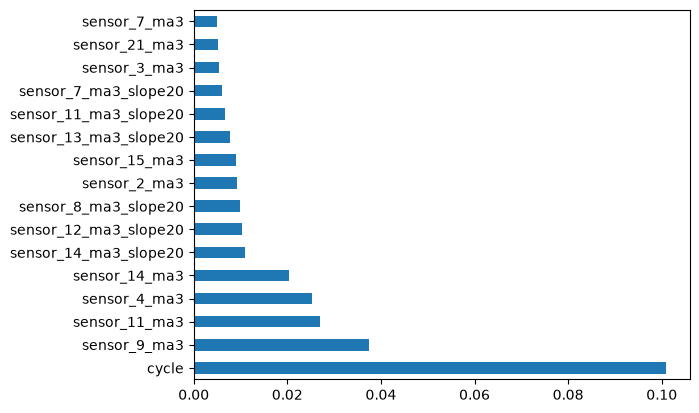

In [29]:

GradientBoosting_pipeline = make_pipeline(
    HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_depth=3,
        max_iter=2000,
        early_stopping=True,
        random_state=42
    )
)
start = time.perf_counter()
GradientBoosting_pipeline.fit(X_train, y_train)
print(f"Gradient Boosting training time: {time.perf_counter() - start:.2f} s")

hgb_perm_result = permutation_importance(
    GradientBoosting_pipeline, X_train, y_train,
    scoring='r2', n_repeats=10, random_state=42, n_jobs=-1,
)
assert isinstance(hgb_perm_result, Bunch)
hgb_perm_importances = pd.Series(hgb_perm_result.importances_mean, index=X_train.columns)
hgb_perm_importances.sort_values(ascending=False).head(16).plot(kind='barh')

In [30]:
hgb_pipeline = make_pipeline(HistGradientBoostingRegressor(learning_rate= 0.05, max_depth=3,max_iter=2000, early_stopping=True, random_state=42))
hgb_choosen = cross_validate(hgb_pipeline, X_train, y_train,cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)

# Poisson

In [31]:
poisson_pipe = make_pipeline(StandardScaler(),PolynomialFeatures(2, include_bias=False),StandardScaler(), PoissonRegressor(alpha=1,max_iter=1000, solver='newton-cholesky'))

# poisson_pipe = make_pipeline(StandardScaler(),PolynomialFeatures(2, include_bias=False),StandardScaler(), PoissonRegressor(max_iter=1000, solver='newton-cholesky'))
poisson_param_grid = {
    # 'poissonregressor__alpha': [0.01, 0.1, 1, 10, 100]
    }

poisson_search = GridSearchCV(
    estimator=poisson_pipe,
    param_grid=poisson_param_grid,
    cv=gkf,
    scoring=scoring,
    refit='r2',
    n_jobs=-1,
)
poisson_search.fit(X_train, y_train, groups=groups)

poisson_cv = poisson_search.cv_results_
i = poisson_search.best_index_
print(f"Poisson: best_params={poisson_search.best_params_}, "
      f"R²={poisson_cv['mean_test_r2'][i]:.4f}, "
      f"RMSE={-poisson_cv['mean_test_rmse'][i]:.4f} (±{poisson_cv['std_test_rmse'][i]:.4f}), "
      f"MSE={-poisson_cv['mean_test_mse'][i]:.4f}, "
      f"NASA={-poisson_cv['mean_test_nasa'][i]:.4f} (±{poisson_cv['std_test_nasa'][i]:.4f})")

Poisson: best_params={}, R²=0.8770, RMSE=14.5963 (±0.7230), MSE=213.5761, NASA=3.9410 (±0.8687)


# Survival Model

In [33]:

# survival_param_grid = {
#     'penalizer': [5],
#     'l1_ratio': [1.0],
# }

# best_survival_params, best_survival_r2, best_survival_results = None, np.inf, None
# best_survival_y_true, best_survival_y_pred = None, None

# for penalizer in survival_param_grid['penalizer']:
#     for l1_ratio in survival_param_grid['l1_ratio']:
#         rmse_scores, mae_scores, r2_scores, nasa_scores = [], [], [], []
#         y_true_folds, y_pred_folds = [], []

#         for train_idx, test_idx in gkf.split(train_df[features], train_df['rul'], train_df['engine_id']):
#             train_fold = train_df.iloc[train_idx]
#             test_fold = train_df.iloc[test_idx]

#             scaler = StandardScaler()
#             X_train = scaler.fit_transform(train_fold[features])
#             X_test = scaler.transform(test_fold[features])

#             lifelines_train = pd.DataFrame(X_train, columns=features)
#             lifelines_train['duration'] = train_fold['cycle'].to_numpy() + train_fold['rul'].to_numpy()
#             lifelines_train['event'] = 1

#             aft = LogLogisticAFTFitter(penalizer=penalizer, l1_ratio=l1_ratio)
#             aft.fit(lifelines_train, duration_col='duration', event_col='event', ancillary=True)

#             lifelines_test = pd.DataFrame(X_test, columns=features)
#             cycle_test = test_fold['cycle'].to_numpy()
#             y_test = test_fold['rul'].to_numpy()

#             rul_pred = aft.predict_median(lifelines_test, conditional_after=cycle_test).to_numpy()
#             rul_pred = np.clip(rul_pred, 0, 125)

#             rmse_scores.append(np.sqrt(np.mean((rul_pred - y_test) ** 2)))
#             mae_scores.append(np.mean(np.abs(rul_pred - y_test)))
#             ss_res = np.sum((y_test - rul_pred) ** 2)
#             ss_tot = np.sum((y_test - y_test.mean()) ** 2)
#             r2_scores.append(1 - ss_res / ss_tot)
#             nasa_scores.append(nasa_score(y_test, rul_pred))
#             y_true_folds.append(y_test)
#             y_pred_folds.append(rul_pred)

#         mean_r2 = np.mean(r2_scores)
#         if mean_r2 < best_survival_r2:
#             best_survival_params = {'penalizer': penalizer, 'l1_ratio': l1_ratio}
#             best_survival_r2 = mean_r2
#             best_survival_y_true = np.concatenate(y_true_folds)
#             best_survival_y_pred = np.concatenate(y_pred_folds)
#             best_survival_results = {
#                 'rmse': np.array(rmse_scores),
#                 'mae': np.array(mae_scores),
#                 'r2': np.array(r2_scores),
#                 'nasa': np.array(nasa_scores),
#             }

# assert best_survival_results is not None
# print(f"LogLogisticAFT: best_params={best_survival_params}, "
#       f"RMSE={best_survival_results['rmse'].mean():.4f} (±{best_survival_results['rmse'].std():.4f}), "
#       f"MAE={best_survival_results['mae'].mean():.4f}, "
#       f"R²={best_survival_results['r2'].mean():.4f}, "
#       f"NASA={best_survival_results['nasa'].mean():.4f} (±{best_survival_results['nasa'].std():.4f})")


# Results

In [32]:
summary_rows = []

def add_cv_row(name, cv):
    summary_rows.append({
        'Model': name,
        'R2_mean': cv['test_r2'].mean(),
        'R2_std': cv['test_r2'].std(),
        'RMSE_mean': -cv['test_rmse'].mean(),
        'RMSE_std': cv['test_rmse'].std(),
        'NASA_mean': -cv['test_nasa'].mean(),
        'NASA_std': cv['test_nasa'].std(),
    })

add_cv_row('Dummy', dummy_results)
add_cv_row('Ridge', ridge_choosen)
add_cv_row('Random Forest', rf_choosen)
add_cv_row('HistGradientBoosting', hgb_choosen)

model_comparison = pd.DataFrame(summary_rows).sort_values('R2_mean',ascending=False).reset_index(drop=True)
model_comparison


,Model,R2_mean,R2_std,RMSE_mean,RMSE_std,NASA_mean,NASA_std
0,HistGradientBoosting,0.888101,0.008100,13.930784,0.508672,3.613342,0.631053
1,Random Forest,0.881650,0.009725,14.324159,0.590283,3.733692,0.411361
2,Ridge,0.856441,0.009575,15.780346,0.536180,4.164565,0.658654
3,Dummy,-0.000001,0.000002,41.672702,0.003385,308.039295,0.576179


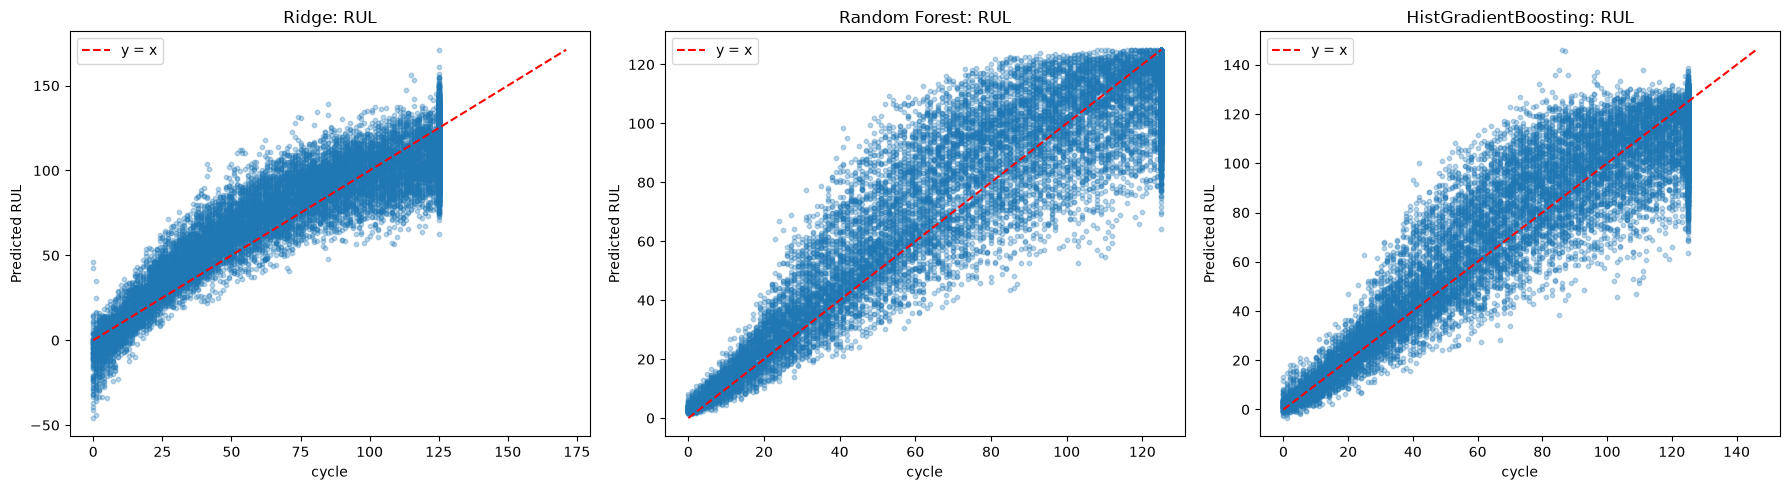

In [34]:

models_to_plot = [
    ('Ridge', ridge_pipe),
    ('Random Forest', RandomForest_pipeline),
    ('HistGradientBoosting', GradientBoosting_pipeline),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.ravel()

for ax, (model_name, estimator) in zip(axes, models_to_plot):
    y_pred = cross_val_predict(estimator, X_train, y_train, cv=gkf, groups=groups, n_jobs=-1)
    ax.scatter(y_train, y_pred, alpha=0.3, s=10)
    lims = [0, max(y_train.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", label="y = x")
    ax.set_xlabel("cycle")
    ax.set_ylabel("Predicted RUL")
    ax.set_title(f"{model_name}: RUL")
    ax.legend()

plt.tight_layout()
plt.show()


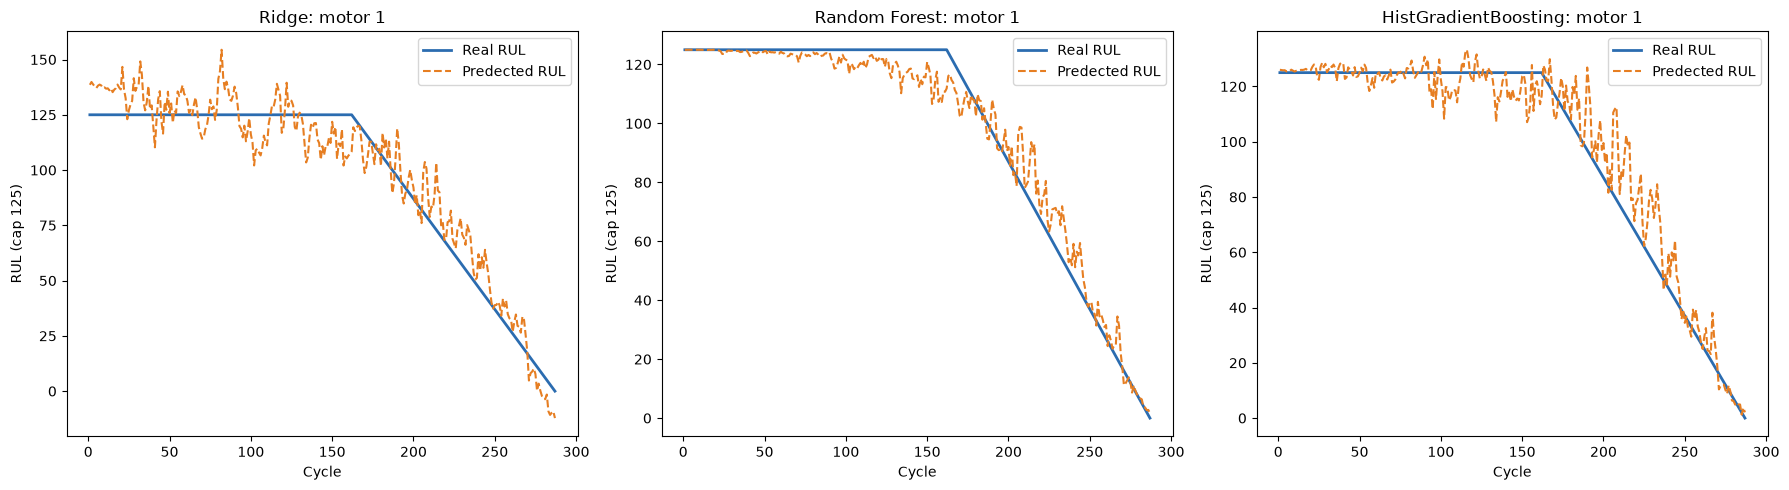

In [35]:
engine1 = train_df[train_df['engine_id'] == 2].sort_values('cycle')
# engine1 = train_df[train_df['engine_id'] == 39].sort_values('cycle'). #Engine with 128 cycles
X1 = engine1[features]
y1_true = engine1['rul_limited']
cycle1 = engine1['cycle']

models_to_plot_engine1 = [
    ('Ridge', ridge_pipe),
    ('Random Forest', RandomForest_pipeline),
    ('HistGradientBoosting', GradientBoosting_pipeline),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.ravel()

for ax, (model_name, estimator) in zip(axes, models_to_plot_engine1):
    y1_pred = estimator.predict(X1)
    ax.plot(cycle1, y1_true, label='Real RUL', color='#2b6cb0', linewidth=2)
    ax.plot(cycle1, y1_pred, label='Predected RUL', color='#e67e22', linewidth=1.5, linestyle='--')
    ax.set_xlabel('Cycle')
    ax.set_ylabel('RUL (cap 125)')
    ax.set_title(f'{model_name}: motor 1')
    ax.legend()

plt.tight_layout()
plt.show()
